## Setup and data loading
Import the libraries used in this notebook (regular expressions, pandas, NumPy, seaborn, matplotlib and python-docx), load the survey data from Excel, and preview the first five rows.

In [1]:
import re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import sys
from docx import Document 

#Loading the data
df = pd.read_excel("Data/Career_Anxiety_due_to_AI.xlsx")
df.head()

,participant_id,university,department,age,gender,academic_year,ai_knowledge,ai_tools_used,career_path,ai_tool_perception,ai_future_perspective,ai_replace_jobs,ai_takeover_time,career_anxiety,consent
0,P0001,Daffodil International University,Department of Computer Science & Engineering,24,Female,4th Year,Medium,"ChatGPT, Quiltbot, Grammarly",Researcher,I don't know for now,"I believe AI will mostly assist humans, with l...",No,Never,Low,Yes
1,P0002,Daffodil International University,Department of Nutrition & Food Engineering,22,Female,2nd Year,Medium,"ChatGPT, Google Gemini, Photomath",Researcher,Google Gemini,I think AI will replace some human jobs but al...,Partially,11–20 years,Medium,Yes
2,P0003,Daffodil International University,Department of Business Administration,22,Female,2nd Year,Low,"ChatGPT, Google Gemini, Microsoft Copilot",Project Manager,Microsoft Copilot,I think AI will replace some human jobs but al...,No,Never,No Anxiety,Yes
3,P0004,Daffodil International University,Department of Nutrition & Food Engineering,21,Female,2nd Year,Low,"ChatGPT, Google Gemini, Don’t know the name",Nutritionist,NaN,I believe AI will significantly replace human ...,Partially,21–50 years,No Anxiety,Yes
4,P0005,Daffodil International University,Department of Nutrition & Food Engineering,21,Male,2nd Year,Medium,"ChatGPT, Google Gemini, Microsoft Copilot",Researcher,ChatGPT,I strongly believe AI cannot take over human a...,No,Never,Low,Yes


## Summary statistics table

We build a table of counts and percentages for university, gender, academic year, AI knowledge, views on whether AI can replace jobs, and career anxiety. We reload the data with `keep_default_na=False` so that the answer "None" for AI knowledge is not treated as missing. The university counts are typed into the code. We print the table and save it, with an age summary in the caption, to a Word file.

In [3]:
# keep_default_na=False stops pandas from dropping the "None" answer
df = pd.read_excel("Data/Career_Anxiety_due_to_AI.xlsx", keep_default_na=False, na_values=[""])

variables = {   # column: (label, category order)
    "gender": ("Gender", ["Male", "Female"]),
    "academic_year": ("Academic year", ["1st Year", "2nd Year", "3rd Year", "4th Year"]),
    "ai_knowledge": ("AI knowledge", ["None", "Low", "Medium", "High"]),
    "ai_replace_jobs": ("Can AI replace human jobs?", ["No", "Partially", "Fully"]),
    "career_anxiety": ("Career anxiety", ["No Anxiety", "Low", "Medium", "High"]),
}

# University is not in the data file, so these counts are typed in
universities = {"Daffodil International University": 1064,
                "American International University-Bangladesh": 693,
                "University of Dhaka": 621,
                "Jahangirnagar University": 566,
                "Chittagong University of Engineering and Technology": 212}

groups = [("University", universities)]
for col, (label, order) in variables.items():
    groups.append((label, df[col].value_counts().reindex(order, fill_value=0)))

rows = [(label if i == 0 else "", cat, f"{n:,}", f"{100 * n / len(df):.1f}")
        for label, counts in groups
        for i, (cat, n) in enumerate(counts.items())]
table = pd.DataFrame(rows, columns=["Variable", "Category", "n", "%"])
print(table.to_string(index=False))

doc = Document()
age = df["age"]
doc.add_paragraph(f"Table 1. Summary statistics of the survey sample (N = {len(df):,}). "
                  f"Age: M = {age.mean():.1f}, SD = {age.std():.1f}, range {age.min()}–{age.max()}.")
word = doc.add_table(rows=1, cols=4, style="Light Shading Accent 1")
for cell, name in zip(word.rows[0].cells, table.columns):
    cell.text = name
for row in table.itertuples(index=False):
    for cell, value in zip(word.add_row().cells, row):
        cell.text = value
doc.save("Table1_summary_statistics.docx")

                  Variable                                            Category     n    %
                University                   Daffodil International University 1,064 33.7
                                  American International University-Bangladesh   693 22.0
                                                           University of Dhaka   621 19.7
                                                      Jahangirnagar University   566 17.9
                           Chittagong University of Engineering and Technology   212  6.7
                    Gender                                                Male 1,932 61.2
                                                                        Female 1,224 38.8
             Academic year                                            1st Year 1,120 35.5
                                                                      2nd Year   985 31.2
                                                                      3rd Year   762 24.1
          

## Average career anxiety by academic year

We convert the career anxiety answers into an ordered score (No Anxiety = 0, Low = 1, Medium = 2, High = 3) and calculate the mean score for each academic year. Averaging assumes the steps between levels are equally spaced.

In [ ]:
# Get the average career anxiety score by academic year
anxiety_order = {
    "No Anxiety": 0,
    "Low": 1,
    "Medium": 2,
    "High": 3
}

df["career_anxiety_score"] = df["career_anxiety"].map(anxiety_order)

avg_career_anxiety = (
    df.groupby("academic_year", observed=True)["career_anxiety_score"]
      .mean()
      .reset_index()
)
avg_career_anxiety.head()

,academic_year,career_anxiety_score
0,1st Year,1.637500
1,2nd Year,1.689340
2,3rd Year,1.706037
3,4th Year,1.733564


## Cleaning the AI tool names

The tool answers are free text, so we use pattern matching to give each tool one standard name and to remove answers that are not tools. We then create a list of tools for each student, a count of tools, and a 0/1 column for each tool used by at least 1% of students. We plot the 10 most common tools and run a Spearman correlation between the number of tools and career anxiety.

*Note:* the survey asked for students' top three tools, so the count has little variation and should not be read as a measure of how much students use AI.

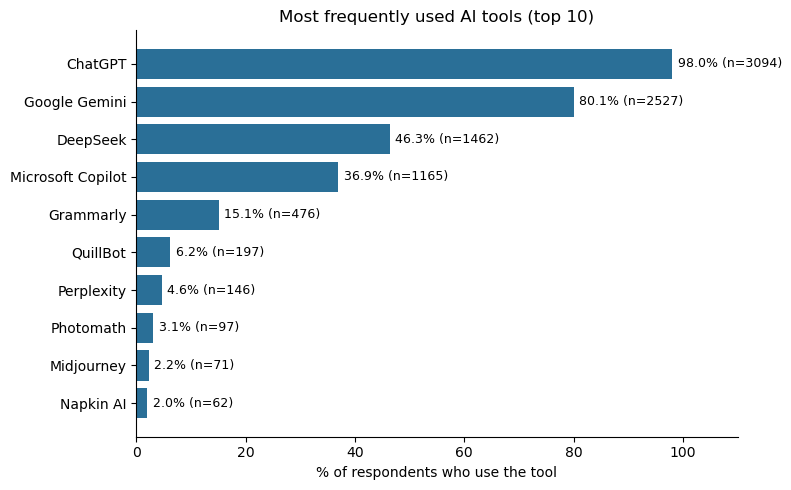

career_anxiety
Medium        1634
Low            648
High           461
No Anxiety     413
Name: count, dtype: int64
Spearman rho (n tools vs anxiety) = 0.024, p = 0.1760


In [ ]:
# ---------------------------------------------------------------
# 1. Clean and standardise the free-text tool names
# ---------------------------------------------------------------
CANON = [  # (regex on lowercase text, standard name)
    (r"chatgpt", "ChatGPT"),
    (r"gemini", "Google Gemini"),
    (r"deep\s?seek", "DeepSeek"),
    (r"github copilot", "GitHub Copilot"),
    (r"copilot", "Microsoft Copilot"),
    (r"grammarly", "Grammarly"),
    (r"quil+bot|quiltbot", "QuillBot"),
    (r"perplexity", "Perplexity"),
    (r"photomath", "Photomath"),
    (r"midjourney", "Midjourney"),
    (r"napkin", "Napkin AI"),
    (r"^(grok|gork)|grok", "Grok"),
    (r"claude", "Claude"),
    (r"black\s?box", "Blackbox AI"),
    (r"leonardo", "Leonardo AI"),
    (r"gamma|gama", "Gamma AI"),
    (r"monica", "Monica AI"),
    (r"manus", "Manus AI"),
    (r"humanize", "Humanize AI"),
    (r"^deep ai", "Deep AI"),
]
NOT_A_TOOL = [r"^$", r"don.?t know", r"i dont use", r"^google$", r"google chrome"]

def clean_tool(t):
    t = t.strip().lower()
    if any(re.search(p, t) for p in NOT_A_TOOL):
        return None
    for pat, name in CANON:
        if re.search(pat, t):
            return name
    return t.title()            # keep rare tools as-is (title-cased)

def parse_tools(cell):
    tools = {clean_tool(t) for t in str(cell).split(",")}
    return sorted(t for t in tools if t)

df["tools_list"] = df["ai_tools_used"].apply(parse_tools)

# ---------------------------------------------------------------
# 2. New variables
# ---------------------------------------------------------------
df["n_ai_tools"] = df["tools_list"].str.len()            # count of tools used (numeric)

# one-hot (0/1) columns for each tool used by >= 1% of respondents
exploded = df["tools_list"].explode().dropna()
freq = exploded.value_counts()
common = freq[freq >= 0.01 * len(df)].index
for tool in common:
    col = "uses_" + re.sub(r"\W+", "_", tool.lower()).strip("_")
    df[col] = df["tools_list"].apply(lambda L: int(tool in L))

# ---------------------------------------------------------------
# 3. Plot most frequently used tools
# ---------------------------------------------------------------
top = freq.head(10).sort_values()
pct = top / len(df) * 100

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top.index, pct, color="#2a6f97")
for b, n, p in zip(bars, top.values, pct):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2,
            f"{p:.1f}% (n={n})", va="center", fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("% of respondents who use the tool")
ax.set_title("Most frequently used AI tools (top 10)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 4. Next step: link to career anxiety (ordinal coding)
# ---------------------------------------------------------------
print(df["career_anxiety"].value_counts())
anx_map = {"No Anxiety": 0, "Low": 1, "Medium": 2, "High": 3}   # adjust to your actual labels
df["career_anxiety_num"] = df["career_anxiety"].map(anx_map)

from scipy.stats import spearmanr
r, p = spearmanr(df["n_ai_tools"], df["career_anxiety_num"], nan_policy="omit")
print(f"Spearman rho (n tools vs anxiety) = {r:.3f}, p = {p:.4f}")

## Grouping intended career paths

We sort the free-text career answers into nine named groups using keyword rules, with unmatched answers labelled "Other". If an answer matches several groups, the keyword that appears first in the text decides. We print the group counts, check what fell into "Other", and plot the percentage of students in each group.

career_group
Software & IT Development          932
Research & Academia                778
Data Science & AI                  640
Business, Finance & Management     300
Cybersecurity & Networking         178
Pharmacy, Health & Food Science    165
Engineering (non-software)          92
Creative, Media & Design            45
Public Service                      20
Other                                6
Name: count, dtype: int64

What landed in 'Other':
career_path
Chef    6


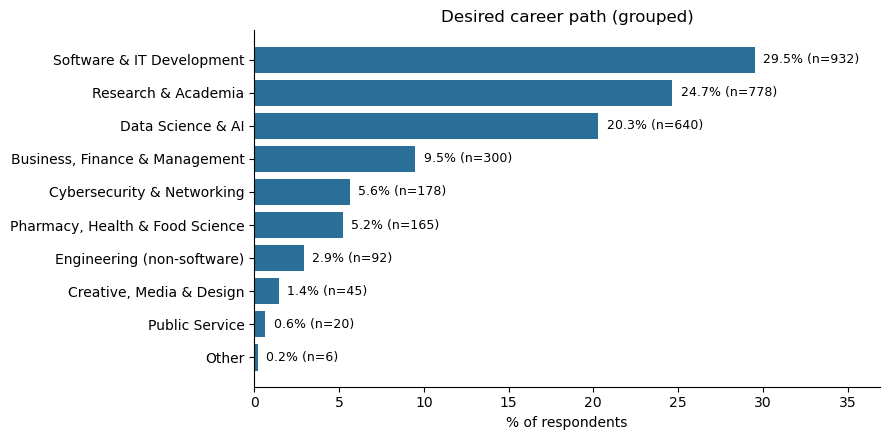

In [ ]:
# Keyword rules -> 6 named groups; everything unmatched = "Other"
# If an answer mentions several careers (e.g. "Software Engineer, Researcher"),
# the group whose keyword appears FIRST in the text is used.
# ---------------------------------------------------------------
GROUPS = {
    "Data Science & AI": r"data|dara|\bai\b|ai/ml|\bml\b|machine learning|artificial",
    "Cybersecurity & Networking": r"cyber|cybet|sequrity|security|hacker|network",
    "Software & IT Development": (r"software|develop|devloper|programm|\bapp\b|application|web\b|game|"
                                  r"devops|java|django|laravel|larabel|backend|front-?end|full stack|"
                                  r"sqa|database|blockchain|computer|tech related"),
    "Research & Academia": (r"rese?a?r?ch|reseac|reasea|researc|reseacrher|teacher|lecturer|professor|"
                            r"faculty|scientist|r&d|bioinformatics"),
    "Business, Finance & Management": (r"business|entrepreneur|trader|bank|account|ceo|cfo|corporate|"
                                       r"market|finance|\bhr\b|manager|director|\bmto\b"),
    "Pharmacy, Health & Food Science": r"pharm|nutrition|physician|doctor|medic|food",
    "Engineering (non-software)": (r"engineer|electr|electical|telecom|textile|maint[ae]n[a-z]*nce|"
                                   r"robo|production"),
    "Creative, Media & Design": (r"design|animat|graphic|content creator|journalis|editor|writer|"
                                 r"novelist|news|media|influenc"),
    "Public Service": r"government|civil service|police|army|military|bcs",
}

def group_career(text):
    t = str(text).strip().lower()
    best, best_pos = "Other", 10**9
    for name, pat in GROUPS.items():
        m = re.search(pat, t)
        if m and m.start() < best_pos:
            best, best_pos = name, m.start()
    return best

df["career_group"] = df["career_path"].apply(group_career)

# Check the result
print(df["career_group"].value_counts())
print("\nWhat landed in 'Other':")
print(df.loc[df["career_group"].str.startswith("Other"), "career_path"]
        .str.strip().value_counts().to_string())

# Plot
counts = df["career_group"].value_counts().sort_values()
pct = counts / len(df) * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(counts.index, pct, color="#2a6f97")
for b, n, p in zip(bars, counts.values, pct):
    ax.text(b.get_width() + 0.5, b.get_y() + b.get_height() / 2,
            f"{p:.1f}% (n={n})", va="center", fontsize=9)
ax.set_xlim(0, pct.max() * 1.25)
ax.set_xlabel("% of respondents")
ax.set_title("Desired career path (grouped)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Preparing the career path and gender comparison

We score self-rated AI knowledge (Low = 1, Medium = 2, High = 3), remove the "Other" career group and students without a Low, Medium or High rating, and order the career groups by their average score. We also set the colours for each gender.

*Note:* the code and plots call this score "AI use", but it measures self-rated AI knowledge, not how often students use AI.

In [ ]:
# AI use vs. career path (career_group) by gender
# AI use = self-rated AI knowledge (Low = 1, Medium = 2, High = 3)
ai_order = {"Low": 1, "Medium": 2, "High": 3}
df["ai_use_score"] = df["ai_knowledge"].map(ai_order)

# Drop the tiny "Other" career group and rows with no AI knowledge answer
d = df[df["career_group"] != "Other"].dropna(subset=["ai_use_score"])

# Order the career groups by their average AI use
career_order = d.groupby("career_group")["ai_use_score"].mean().sort_values().index

gender_colors = {"Male": "#257de0", "Female": "#f47230"}

### AI knowledge score by career path and gender

We plot the mean AI knowledge score for each career group, separately for male and female students. The dots are means and the lines are 95% confidence intervals.

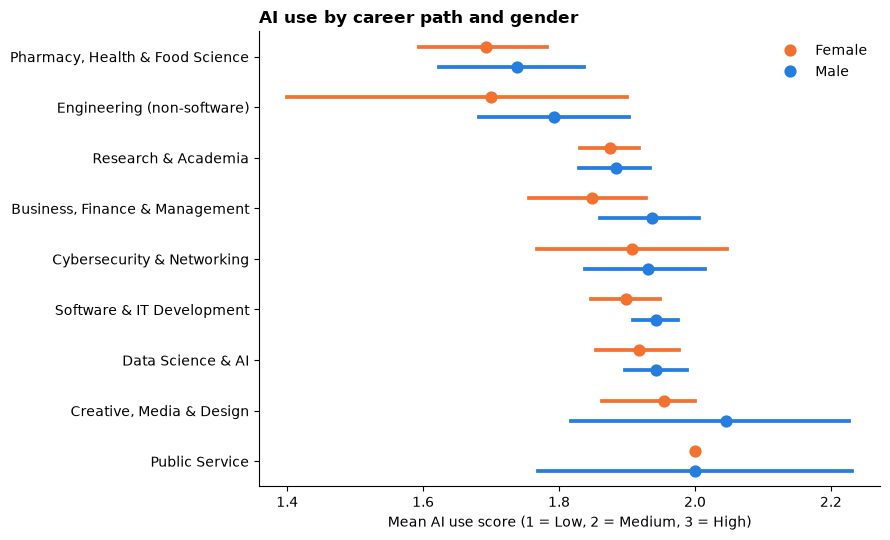

In [ ]:
# Average AI use by career group and gender (dots = mean, lines = 95% CI)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.pointplot(data=d, x="ai_use_score", y="career_group", hue="gender",
              order=career_order, palette=gender_colors, dodge=0.4,
              linestyle="none", ax=ax)
ax.set_xlabel("Mean AI use score (1 = Low, 2 = Medium, 3 = High)")
ax.set_ylabel("")
ax.set_title("AI use by career path and gender", loc="left", fontweight="bold")
ax.legend(title="", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Distribution of AI knowledge within each career path

We draw stacked bars showing the percentage of Low, Medium and High AI knowledge in each career group, with one panel for each gender.

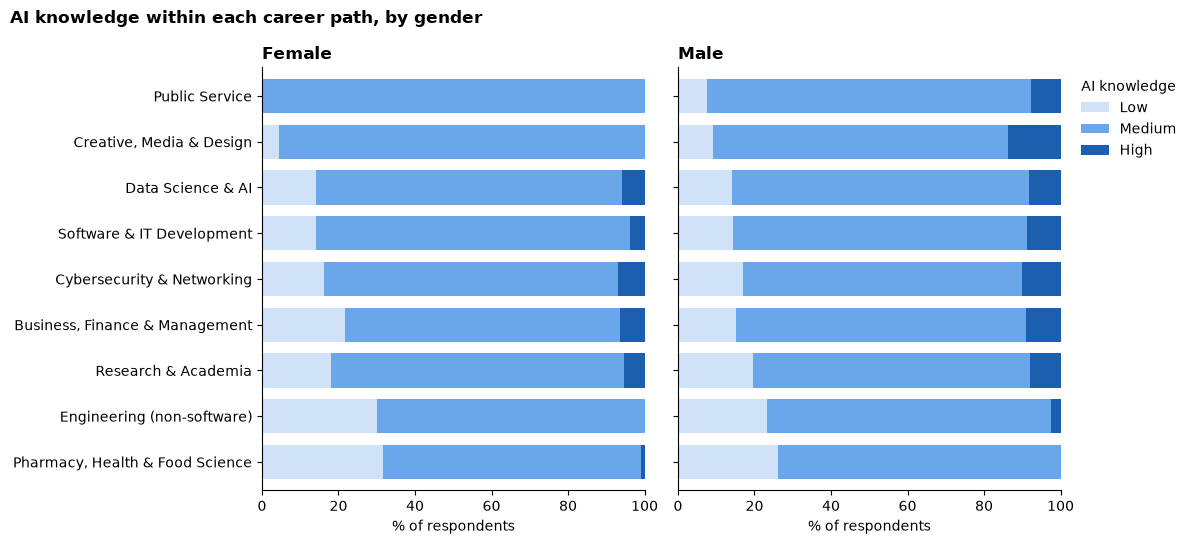

In [ ]:
# Share of Low / Medium / High AI use within each career group, one panel per gender
levels = ["Low", "Medium", "High"]
level_colors = ["#cfe2f7", "#6aa7ea", "#1b5fae"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for ax, g in zip(axes, ["Female", "Male"]):
    sub = d[d["gender"] == g]
    pct = (pd.crosstab(sub["career_group"], sub["ai_knowledge"], normalize="index") * 100)
    pct = pct.reindex(index=career_order, columns=levels)
    pct.plot.barh(stacked=True, color=level_colors, width=0.75, ax=ax, legend=False)
    ax.set_title(g, loc="left", fontweight="bold")
    ax.set_xlabel("% of respondents")
    ax.set_ylabel("")
    ax.spines[["top", "right"]].set_visible(False)

axes[1].legend(title="AI knowledge", frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("AI knowledge within each career path, by gender", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

### Career anxiety by AI knowledge and gender

We plot the mean career anxiety score (0 to 3) at each AI knowledge level for male and female students, with 95% confidence intervals.

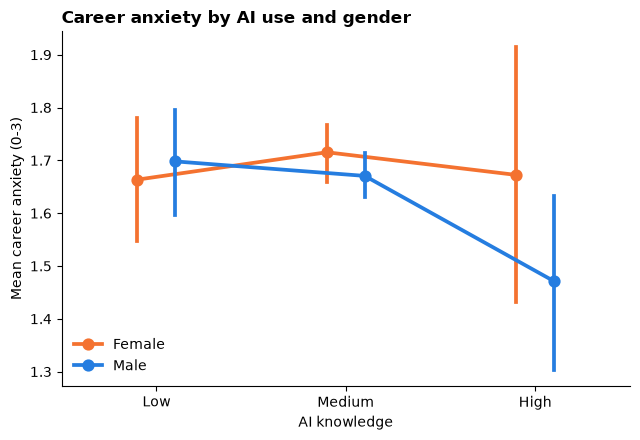

In [ ]:
# Average career anxiety by AI use level and gender
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.pointplot(data=d, x="ai_knowledge", y="career_anxiety_score", hue="gender",
              order=levels, palette=gender_colors, dodge=0.2, ax=ax)
ax.set_xlabel("AI knowledge")
ax.set_ylabel("Mean career anxiety (0-3)")
ax.set_title("Career anxiety by AI use and gender", loc="left", fontweight="bold")
ax.legend(title="", frameon=False, loc="lower left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## AI use and employment uncertainty

The data has no question about learning, so this section only covers **employment uncertainty**.
It is measured by combining three survey questions (each rescaled to 0-1, then averaged):
`ai_replace_jobs`, `ai_takeover_time` and `ai_future_perspective`. Higher = more uncertain / worried about jobs.

### Building the index and testing correlations

We rescale the three job-related answers to a 0 to 1 range and average them into the employment uncertainty index. Higher values reflect stronger or sooner expected job replacement. We then run two Spearman correlations: AI knowledge with the index, and the index with career anxiety.

In [ ]:
# Employment uncertainty index (0 = least uncertain, 1 = most uncertain)
replace_map = {"No": 0, "Partially": 1, "Fully": 2}

takeover_map = {"Never": 0, "50+ years": 1, "21–50 years": 2,
                "11–20 years": 3, "6–10 years": 4, "1–5 years": 5}

future_map = {
    "I strongly believe AI cannot take over human activities and will be a helpful tool for humans.": 0,
    "I believe AI will mostly assist humans, with limited job replacement.": 1,
    "I think AI will replace some human jobs but also create new opportunities.": 2,
    "I believe AI will significantly replace human jobs and create major challenges.": 3,
    "I strongly believe AI will completely take over human jobs and pose serious threat to humanity.": 4,
}

# Rescale each question to 0-1, then average the three
parts = pd.DataFrame({
    "replace": df["ai_replace_jobs"].map(replace_map) / 2,
    "takeover": df["ai_takeover_time"].map(takeover_map) / 5,
    "future": df["ai_future_perspective"].map(future_map) / 4,
})
df["employment_uncertainty"] = parts.mean(axis=1)

# AI use (Low = 1, Medium = 2, High = 3); rows with no AI knowledge answer are left out
df["ai_use_score"] = df["ai_knowledge"].map({"Low": 1, "Medium": 2, "High": 3})
u = df.dropna(subset=["ai_use_score", "employment_uncertainty"])

gender_colors = {"Male": "#257de0", "Female": "#f47230"}
levels = ["Low", "Medium", "High"]

# Quick correlations (Spearman)
r1, p1 = spearmanr(u["ai_use_score"], u["employment_uncertainty"])
r2, p2 = spearmanr(df["employment_uncertainty"], df["career_anxiety_score"])
print(f"AI use vs employment uncertainty:     rho = {r1:.3f}, p = {p1:.4f}")
print(f"Employment uncertainty vs anxiety:    rho = {r2:.3f}, p = {p2:.4f}")

AI use vs employment uncertainty:     rho = -0.008, p = 0.6414
Employment uncertainty vs anxiety:    rho = 0.154, p = 0.0000


### Employment uncertainty by AI knowledge and gender

We plot the mean employment uncertainty index at each AI knowledge level for each gender, with 95% confidence intervals.

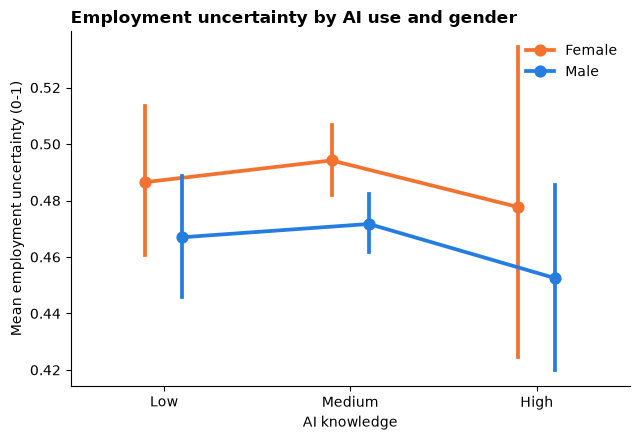

In [ ]:
# Plot 4: employment uncertainty by AI use level (dots = mean, lines = 95% CI)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.pointplot(data=u, x="ai_knowledge", y="employment_uncertainty", hue="gender",
              order=levels, palette=gender_colors, dodge=0.2, ax=ax)
ax.set_xlabel("AI knowledge")
ax.set_ylabel("Mean employment uncertainty (0-1)")
ax.set_title("Employment uncertainty by AI use and gender", loc="left", fontweight="bold")
ax.legend(title="", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Views on job replacement by AI knowledge

We show, for each AI knowledge level, the percentage of students who think AI can replace human jobs fully, partially or not at all.

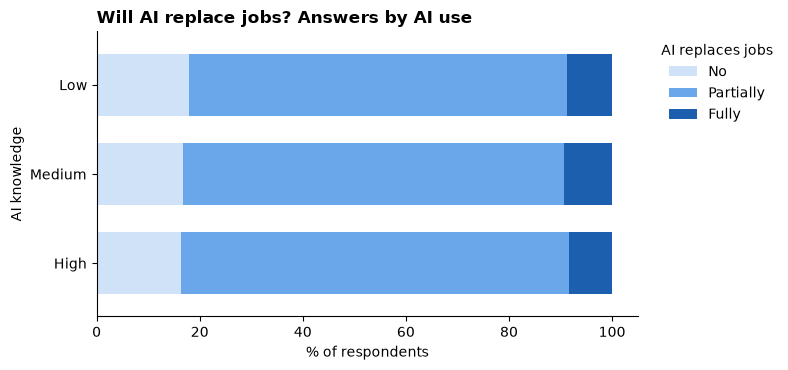

In [ ]:
# Plot 5: do students with different AI use think AI will replace jobs?
pct = pd.crosstab(u["ai_knowledge"], u["ai_replace_jobs"], normalize="index") * 100
pct = pct.reindex(index=levels[::-1], columns=["No", "Partially", "Fully"])

ax = pct.plot.barh(stacked=True, color=["#cfe2f7", "#6aa7ea", "#1b5fae"], width=0.7, figsize=(8, 3.8))
ax.set_xlabel("% of respondents")
ax.set_ylabel("AI knowledge")
ax.set_title("Will AI replace jobs? Answers by AI use", loc="left", fontweight="bold")
ax.legend(title="AI replaces jobs", frameon=False, loc="upper left", bbox_to_anchor=(1.02, 1))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Career anxiety by employment uncertainty

We split students into Low, Medium and High uncertainty groups of roughly similar size (tied scores can make them unequal) and compare mean career anxiety across the groups for each gender.

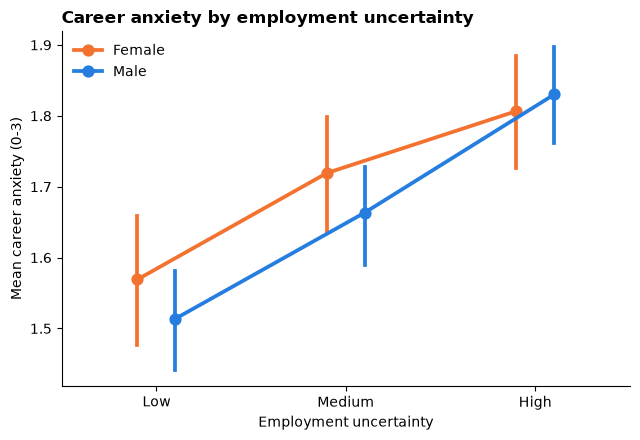

In [ ]:
# Plot 6: employment uncertainty and career anxiety
# Group students into Low / Medium / High uncertainty (equal-sized thirds)
df["uncertainty_group"] = pd.qcut(df["employment_uncertainty"], 3, labels=levels)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.pointplot(data=df, x="uncertainty_group", y="career_anxiety_score", hue="gender",
              order=levels, palette=gender_colors, dodge=0.2, ax=ax)
ax.set_xlabel("Employment uncertainty")
ax.set_ylabel("Mean career anxiety (0-3)")
ax.set_title("Career anxiety by employment uncertainty", loc="left", fontweight="bold")
ax.legend(title="", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Is AI knowledge associated with career anxiety?

We flag students who report high career anxiety and set AI knowledge as an ordered category (Low, Medium, High), which leaves "None" answers out. The first plot shows the mix of anxiety levels at each knowledge level. The second shows the proportion with high anxiety by view on job replacement and AI knowledge, to explore a possible interaction.

*Note:* some subgroups are small (for example, High knowledge with the answer "Fully"), and no statistical test of the interaction is run here.

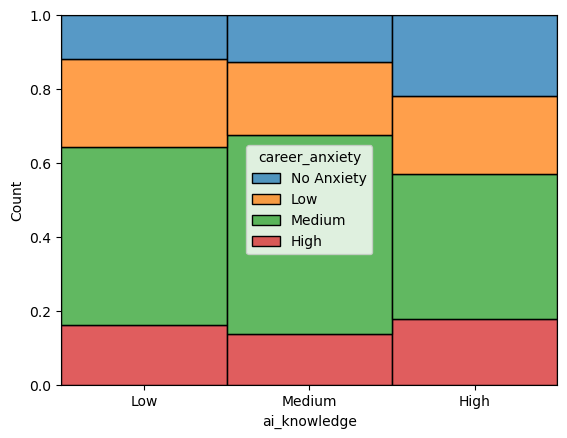

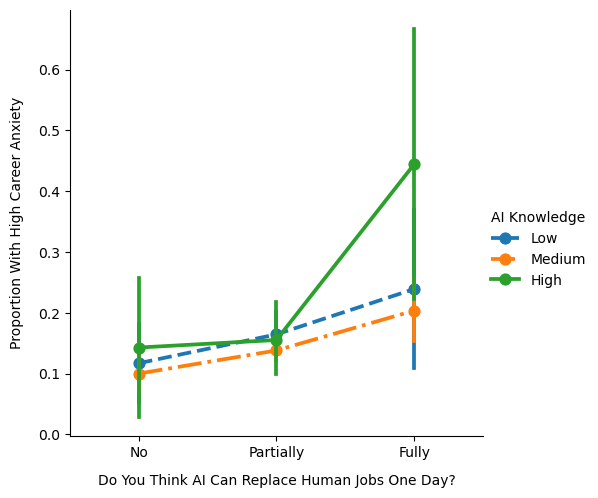

In [ ]:
# https://seaborn.pydata.org/tutorial
# Is higher AI knowledge associated with more or less career anxiety? 
df["high_anxiety_indicator"] = np.where(df["career_anxiety"] == "High", 1, 0)

df["ai_knowledge"] = pd.Categorical(df["ai_knowledge"],
                                    categories=["Low", "Medium", "High"],
                                    ordered=True)

sns.histplot(data=df, x="ai_knowledge", hue="career_anxiety", multiple="fill",
            hue_order=["No Anxiety", "Low", "Medium", "High"])

# From this graph, we can notice that the high bar has noticeably larger No Anxiety and High Anxiety sections.
# There is no clear direction they seem to be either or

# Is higher AI knowledge associated with more or less career anxiety? 
g = sns.catplot(
    data=df, x="ai_replace_jobs", y="high_anxiety_indicator", hue="ai_knowledge", kind="point",
    linestyles=["--", "-.", "-"],
    hue_order=["Low", "Medium", "High"]
)
g.set_axis_labels("Do You Think AI Can Replace Human Jobs One Day?", "Proportion With High Career Anxiety", labelpad=10)
g.legend.set_title("AI Knowledge")

# From this graph we can see that the porportion of students with high anxiety shoots up when knowledge is combined with belief (interaction term)
# One critique: The error bar is larger because it is based on a smaller group


## Web-scraped university social media data

We load the classified social media posts collected from university accounts and clubs and display them. The file includes the platform, account, link, caption, university and club, along with flags and matched keywords showing whether a post is about AI, an event, or an AI event. The scraping and classification steps are not part of this notebook.

In [ ]:
classified = pd.read_csv("Data/bangladesh_universities_ai_promotion_classified.csv")
classified

,platform,handle,url,caption,university,club,is_ai,is_event,ai_event,ai_matches,event_matches
0,instagram,ju.ieee,https://www.instagram.com/p/CyHMzQbR3PJ/,NaN,Jahangirnagar University,IEEE JU Student Branch,False,False,False,[],[]
1,instagram,ju.ieee,https://www.instagram.com/p/CyHMyIux8VG/,NaN,Jahangirnagar University,IEEE JU Student Branch,False,False,False,[],[]
2,instagram,ju.ieee,https://www.instagram.com/p/CyHMxECR0tU/,NaN,Jahangirnagar University,IEEE JU Student Branch,False,False,False,[],[]
3,instagram,ju.ieee,https://www.instagram.com/p/DdrbJCeoCdj/,Come join us for our Soldering Workshop!!! Don...,Jahangirnagar University,IEEE JU Student Branch,False,True,False,[],"['join us', 'workshop']"
4,instagram,ju.ieee,https://www.instagram.com/p/DW6_72GEXps/,⚡ REMINDER: IEEE Soldering Masterclass is TOMO...,Jahangirnagar University,IEEE JU Student Branch,False,True,False,[],['masterclass']
...,...,...,...,...,...,...,...,...,...,...,...
435,facebook,https://www.facebook.com/aiubartsclub,https://www.facebook.com/aiubartsclub/posts/pf...,"🎉 𝐇𝐀𝐏𝐏𝐘 𝐁𝐈𝐑𝐓𝐇𝐃𝐀𝐘, 𝐏𝐑𝐀𝐍𝐉𝐀𝐘 𝐆𝐇𝐎𝐒𝐄! 🎂\r\n\r\nThe ...",American International University-Bangladesh,AIUB Arts Club,False,False,False,[],[]
436,facebook,https://www.facebook.com/aiubartsclub,https://www.facebook.com/aiubartsclub/posts/pf...,🪔 শুভ দীপাবলি | 𝐀𝐈𝐔𝐁 𝐀𝐑𝐓𝐒 𝐂𝐋𝐔𝐁 🪔\r\n\r\nআলোর এ...,American International University-Bangladesh,AIUB Arts Club,False,False,False,[],[]
437,facebook,https://www.facebook.com/aiubartsclub,https://www.facebook.com/aiubartsclub/posts/pf...,⏳ 𝐎𝐍𝐋𝐘 𝐀 𝐅𝐄𝐖 𝐇𝐎𝐔𝐑𝐒 𝐋𝐄𝐅𝐓! 🎨\r\n\r\nThis is your...,American International University-Bangladesh,AIUB Arts Club,False,False,False,[],[]
438,facebook,https://www.facebook.com/aiubartsclub,https://www.facebook.com/aiubartsclub/posts/pf...,"🎉𝐇𝐀𝐏𝐏𝐘 𝐁𝐈𝐑𝐓𝐇𝐃𝐀𝐘, 𝐍𝐈𝐀𝐙 𝐌𝐀𝐉𝐔𝐌𝐃𝐀𝐑 𝐒𝐈𝐑 🎂\r\n\r\nTh...",American International University-Bangladesh,AIUB Arts Club,False,False,False,[],[]
